In a dilute liquid-phase reactor the reaction A + b = C reaches equilibrium . Initial concentration are [A] = 0.5 , [B] = 0.5 and {c} = 0 mol/l . if X mol/L of c is formed , Kc = x/(0.5 -x)^2 , which rearrange to th quadratic equation 
Kc.x^2- ( kc + 1)x + 0.25Kc = 0

write a pytho program that :
1 reads Kc using input() , prints the data type of the raw input and of the converted valve , and shows a clear message (no crash) if the text is not a number or if kc greater or equal to 0
2 finds a,b,c the discriminant and both roots ;
3 selescts the physically meaningful roots (o<_ x <_ 0.5);
4 prints equilibrium [A] , [B] , [C] (3 decimals) and the coversion of the limiting reactant = x / [A]* 100 (%);
5 classifies the conversion using if/ elif / else : _> 70 % " high" , _>40 % " moderate" , otherwise "low".
  test with Kc = 6 , kc = 0.5 , Kc = abc and Kc = -2

In [13]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted value type:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Error: Kc must be a positive number greater than 0.")
    else:
        # Kc*x^2 - (Kc + 1)*x + 0.25*Kc = 0
        a = kc
        b = -(kc + 1)
        c = 0.25 * kc
        discriminant = b**2 - 4 * a * c

        print(f"a = {a}, b = {b}, c = {c}")
        print(f"Discriminant = {discriminant}")

        if discriminant < 0:
            print("Error: The equation has no real roots.")
        else:
            root1 = (-b + math.sqrt(discriminant)) / (2 * a)
            root2 = (-b - math.sqrt(discriminant)) / (2 * a)
            print(f"Root 1 = {root1}")
            print(f"Root 2 = {root2}")

            physical_roots = [root for root in (root1, root2) if 0 <= root <= 0.5]
            if not physical_roots:
                print("Error: No root is physically meaningful (0 <= x <= 0.5).")
            else:
                x = physical_roots[0]
                concentration_a = 0.5 - x
                concentration_b = 0.5 - x
                concentration_c = x
                conversion = x / 0.5 * 100

                print(f"Equilibrium [A] = {concentration_a:.3f} mol/L")
                print(f"Equilibrium [B] = {concentration_b:.3f} mol/L")
                print(f"Equilibrium [C] = {concentration_c:.3f} mol/L")
                print(f"Conversion = {conversion:.3f}%")

                if conversion >= 70:
                    classification = "high"
                elif conversion >= 40:
                    classification = "moderate"
                else:
                    classification = "low"
                print(f"Conversion classification: {classification}")

Raw input type: <class 'str'>
Converted value type: <class 'float'>
a = 0.5, b = -1.5, c = 0.125
Discriminant = 2.0
Root 1 = 2.914213562373095
Root 2 = 0.08578643762690485
Equilibrium [A] = 0.414 mol/L
Equilibrium [B] = 0.414 mol/L
Equilibrium [C] = 0.086 mol/L
Conversion = 17.157%
Conversion classification: low


part A . A pollutant in wastewater is degraded in a batch photoreactor by a first order reaction , dc/dt = -Kc. use the euler method : C_new = c_old -k*c_old -delta T . take C = 1.0 mol/l , K = 0.12 per min , delta t = o.5 min
1 using a for loop , simulate 5 minutes and print a table of time (min) , concentration (mol/L) and Coversion (%)
2 using a math.exp() , calculate the exact valve Ce^(-kt) at 5 min and print  the absolute error of the euler result 
3 using a while loop, reapeat the simultation until conversion reaches 70% or time reaches 100  min . print the time needed and the final concentration 

 part B . storage tank lots such as TK0045-LOT19 are stored as text . write a programme that reads a lot code , loops through each character , and prints the number of digits and the sum of the digits . show a message for an empty code and for code with no digits .

In [10]:
import math

initial_concentration = 1.0
rate_constant = 0.12
time_step = 0.5

# Euler simulation for the first 5 minutes.
concentration = initial_concentration
elapsed_time = 0.0
steps_to_five_minutes = int(5 / time_step)

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{elapsed_time:.1f}\t\t{concentration:.4f}\t\t\t0.00")

for step in range(1, steps_to_five_minutes + 1):
    concentration = concentration - rate_constant * concentration * time_step
    elapsed_time = step * time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{elapsed_time:.1f}\t\t{concentration:.4f}\t\t\t{conversion:.2f}")

euler_concentration = concentration
exact_concentration = initial_concentration * math.exp(-rate_constant * 5)
absolute_error = abs(euler_concentration - exact_concentration)

print(f"\nExact concentration at 5 min = {exact_concentration:.6f} mol/L")
print(f"Absolute error at 5 min = {absolute_error:.6f} mol/L")

# Continue with Euler's method until conversion reaches 70% or time reaches 100 min.
concentration = initial_concentration
elapsed_time = 0.0
conversion = 0.0

while conversion < 70 and elapsed_time < 100:
    concentration = concentration - rate_constant * concentration * time_step
    elapsed_time += time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100

print(f"\nTime to reach 70% conversion (or 100 min) = {elapsed_time:.1f} min")
print(f"Final concentration = {concentration:.4f} mol/L")
print(f"Final conversion = {conversion:.2f}%")

lot_code = input("Enter a storage tank lot code: ")
if lot_code == "":
    print("The lot code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in lot_code:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The lot code contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")

Time (min)	Concentration (mol/L)	Conversion (%)
0.0		1.0000			0.00
0.5		0.9400			6.00
1.0		0.8836			11.64
1.5		0.8306			16.94
2.0		0.7807			21.93
2.5		0.7339			26.61
3.0		0.6899			31.01
3.5		0.6485			35.15
4.0		0.6096			39.04
4.5		0.5730			42.70
5.0		0.5386			46.14

Exact concentration at 5 min = 0.548812 mol/L
Absolute error at 5 min = 0.010197 mol/L

Time to reach 70% conversion (or 100 min) = 10.0 min
Final concentration = 0.2901 mol/L
Final conversion = 70.99%
Number of digits: 6
Sum of digits: 19


Part A . A plant has n candidate feed components and wants to blend r of them (order does not matter ) . write a  recursive function factoral (n) (remember the base case fo 0!) and a function combination (n,r)= n! /{r!(n-r)!} that uses it . rejects invalid input (negative values ,r>n). print the number of possible blends fpr n = 8 ,r=4 and show the message for n=3 , r=5 .

Part B. During a cooling experiment , temperature readings are taken at times = fibonacci number * 3 min . write an iterative function fib_iter(n) that returns a list n fibonacci numbers, and a recursive function fib_rec(k) that returns the k-th fibonacci number (F=0 , F1=1) . for n =8 , check that both functions agree and print a table : reading No | fibonacci tag | Time (min)


In [11]:
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if n < 0:
        raise ValueError("n must not be negative.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if not isinstance(r, int) or isinstance(r, bool):
        raise TypeError("r must be an integer.")
    if n < 0 or r < 0:
        raise ValueError("n and r must not be negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Part A: Combinations")
print("Number of blends for n=8, r=4:", combination(8, 4))

try:
    print("Number of blends for n=3, r=5:", combination(3, 5))
except ValueError as error:
    print("Invalid combination for n=3, r=5:", error)


def fib_iter(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if n < 0:
        raise ValueError("n must not be negative.")

    sequence = []
    first, second = 0, 1
    for _ in range(n):
        sequence.append(first)
        first, second = second, first + second
    return sequence


def fib_rec(k):
    if not isinstance(k, int) or isinstance(k, bool):
        raise TypeError("k must be an integer.")
    if k < 0:
        raise ValueError("k must not be negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


print("\nPart B: Fibonacci readings")
number_of_readings = 8
fibonacci_values = fib_iter(number_of_readings)
recursive_values = [fib_rec(index) for index in range(number_of_readings)]
print("Iterative and recursive values agree:", fibonacci_values == recursive_values)
print("Reading No | Fibonacci tag | Time (min)")
for reading_number, fibonacci_tag in enumerate(fibonacci_values, start=1):
    time_minutes = fibonacci_tag * 3
    print(f"{reading_number:10} | {fibonacci_tag:13} | {time_minutes:10}")

Part A: Combinations
Number of blends for n=8, r=4: 70
Invalid combination for n=3, r=5: r cannot be greater than n.

Part B: Fibonacci readings
Iterative and recursive values agree: True
Reading No | Fibonacci tag | Time (min)
         1 |             0 |          0
         2 |             1 |          3
         3 |             1 |          3
         4 |             2 |          6
         5 |             3 |          9
         6 |             5 |         15
         7 |             8 |         24
         8 |            13 |         39


photocatalytic degradation of a dye was studied at two UV intensities . the concentration (mol/l) was recorded :
Time_min Run1_mol_L(low UV) Run2_mol_l(high UV)
0 0.80 0.80
10 0.54 0.44
20 0.36 0.24
30 0.24 0.13
40 0.16 0.07
50 0.11 0.04

(1) create a dataframe from the table . save it as kinectics.csv (without index column) and as kinetic.json . Read the csv back and print its shape and data types
(2) print the mean and standard deviation of Run1 and Run2 , and state which run shows more variation
(3) plot both runs on one graph (time on x-axis) with title , axis labels with units , legend and grid
(4) Air is compressed slowly im a piston-cylinder vessel at constant temperature :
volume_L 2 3 4 5 6
pressure_bar 3.01 1.98 1.52 1.19 1.01

plot pressue vs volume as a scatter plot . calculate k as the mean P*V and draw the reference curve p= k/v on the same graph .add title with , labels with units and legend.

CSV shape: (6, 3)
CSV data types:
Time_min                int64
Run1_mol_L_low_UV     float64
Run2_mol_L_high_UV    float64
dtype: object

Run 1 mean: 0.3683 mol/L
Run 1 standard deviation: 0.2617 mol/L
Run 2 mean: 0.2867 mol/L
Run 2 standard deviation: 0.2904 mol/L
Run 2 shows more variation.


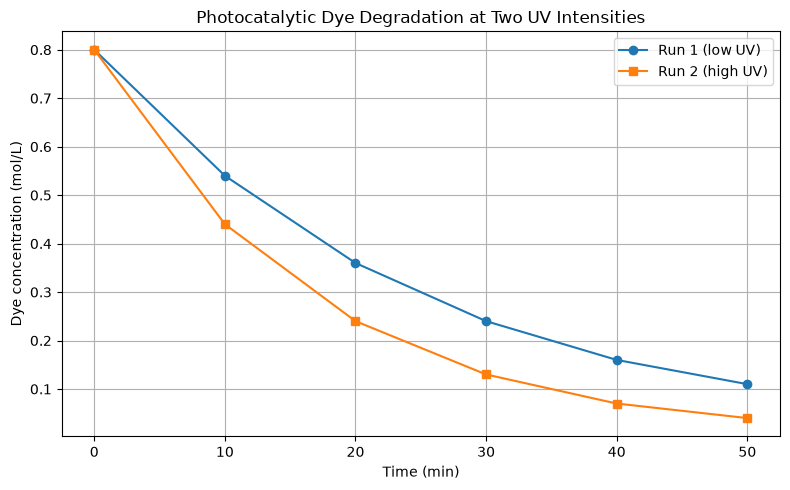


Mean P*V (k) = 6.0100 bar L


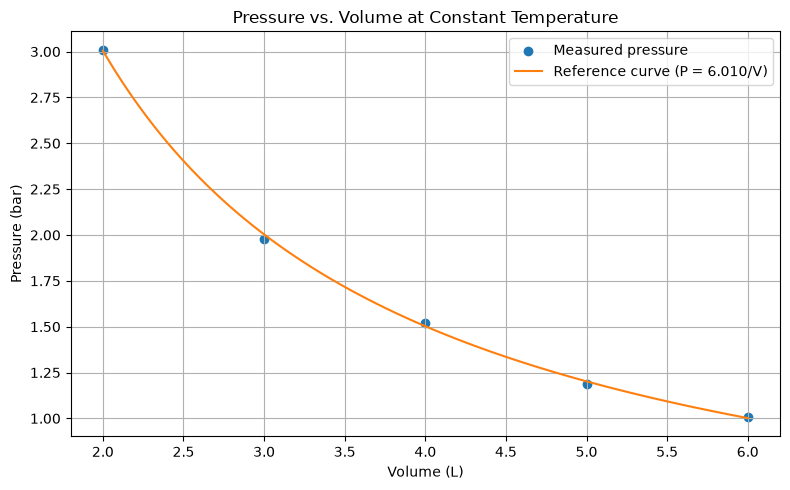

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Dye degradation measurements at two UV intensities.
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L_low_UV": [0.80, 0.54, 0.36, 0.24, 0.16, 0.11],
    "Run2_mol_L_high_UV": [0.80, 0.44, 0.24, 0.13, 0.07, 0.04],
})

kinetics_df.to_csv("kinectics.csv", index=False)
kinetics_df.to_json("kinetic.json", orient="records", indent=4)

kinetics_from_csv = pd.read_csv("kinectics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics_from_csv["Run1_mol_L_low_UV"].mean()
run1_std = kinetics_from_csv["Run1_mol_L_low_UV"].std()
run2_mean = kinetics_from_csv["Run2_mol_L_high_UV"].mean()
run2_std = kinetics_from_csv["Run2_mol_L_high_UV"].std()

print(f"\nRun 1 mean: {run1_mean:.4f} mol/L")
print(f"Run 1 standard deviation: {run1_std:.4f} mol/L")
print(f"Run 2 mean: {run2_mean:.4f} mol/L")
print(f"Run 2 standard deviation: {run2_std:.4f} mol/L")
if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

plt.figure(figsize=(8, 5))
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run1_mol_L_low_UV"], marker="o", label="Run 1 (low UV)")
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run2_mol_L_high_UV"], marker="s", label="Run 2 (high UV)")
plt.title("Photocatalytic Dye Degradation at Two UV Intensities")
plt.xlabel("Time (min)")
plt.ylabel("Dye concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Pressure-volume measurements and mean P*V reference curve.
volume_l = [2, 3, 4, 5, 6]
pressure_bar = [3.01, 1.98, 1.52, 1.19, 1.01]
pv_products = [volume * pressure for volume, pressure in zip(volume_l, pressure_bar)]
k_mean = sum(pv_products) / len(pv_products)
print(f"\nMean P*V (k) = {k_mean:.4f} bar L")

volume_curve = [min(volume_l) + index * (max(volume_l) - min(volume_l)) / 100 for index in range(101)]
pressure_curve = [k_mean / volume for volume in volume_curve]

plt.figure(figsize=(8, 5))
plt.scatter(volume_l, pressure_bar, color="tab:blue", label="Measured pressure")
plt.plot(volume_curve, pressure_curve, color="tab:orange", label=f"Reference curve (P = {k_mean:.3f}/V)")
plt.title("Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()